In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
FIG, TAB, PRED = ROOT/"results"/"figures", ROOT/"results"/"tables", ROOT/"results"/"predictions"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12})
def savefig(name):
    plt.savefig(FIG/f"{name}.png", bbox_inches="tight"); print("saved ->", f"results/figures/{name}.png")
pd.set_option("display.width", 160, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")

# 10 · Explainability and the rainfall-response profile

Proposal objective: *"an explainable characterisation of critical rainfall exposure windows"*. We triangulate three independent lenses on the
same 16 weekly lags so that no conclusion rests on one method:

1. **TreeSHAP** on the trained XGBoost model (what the *predictor* uses) - exact path-dependent TreeSHAP via `Booster.predict(pred_contribs=True)`.
2. **Permutation importance** on the held-out test years (what *hurts accuracy* when a week is scrambled).
3. **Panel fixed-effects distributed-lag regression** on `log(yield)` with district and year fixed effects, clustered by district
   (what the data say about the *effect* of a +100 mm anomaly in each week, with confidence intervals and joint tests).

> Caveat (also in `docs/limitations.md`): SHAP and permutation importance describe model behaviour; only the fixed-effects regression
> has a (conditional) causal-style reading, and even it assumes weather anomalies are as-good-as-random given the fixed effects.

In [2]:
import json
from src.experiment import *
from src.explain import *
from src.panel import lag_coefficients, stage_coefficients, fit_fe, _prep
from src.weather_features import STAGES
D = pd.read_csv(ROOT/"data/processed/phase2_lag_features.csv.gz"); D = add_rain_anomalies(D, 2009)
HP = json.load(open(TAB/"p2_main_hyperparameters.json"))
STAGE_COLOR = dict(zip(STAGES, ["#e9c46a", "#8ab17d", "#2a9d8f", "#e76f51", "#6d597a"]))
def stage_bands(ax, ymax=None):
    # lags are plotted at x = -k; stage k-sets are inclusive
    for (s, ks), c in zip(STAGES.items(), STAGE_COLOR.values()):
        ax.axvspan(-max(ks) - .5, -min(ks) + .5, color=c, alpha=.13, lw=0)

## 1 · Train the explained models and compute TreeSHAP on the held-out test years

In [3]:
parts = split_frame(D)
def fit_xgb(tier, fs):
    cols = FEATURE_SETS[fs]; mode = "anomaly" if tier == "C_anomaly" else "level"
    X, y, names, enc = design_matrices(parts, cols)
    base = {k: (v[BASE_COL].to_numpy() if mode == "anomaly" else np.zeros(len(v))) for k, v in parts.items()}
    p = HP[f"{tier}|{fs}|XGB"]; m = fit_model("XGB", p, X, {k: y[k] - base[k] for k in y}, 42)
    return m, X, {k: y[k] - base[k] for k in y}, names, base
models = {}
for key in [("C_anomaly", "F7_Lag16_Anomaly"), ("C_anomaly", "F5_Lag16"), ("A_weather_only", "F5_Lag16"), ("A_weather_only", "F7_Lag16_Anomaly")]:
    models[key] = fit_xgb(*key)
    m, X, y, names, base = models[key]; print(key, "test MAE (kg/ha):", round(np.mean(np.abs(y["test"] - m.predict(X["test"]))), 1))

('C_anomaly', 'F7_Lag16_Anomaly') test MAE (kg/ha): 336.2


('C_anomaly', 'F5_Lag16') test MAE (kg/ha): 337.8


('A_weather_only', 'F5_Lag16') test MAE (kg/ha): 744.4


('A_weather_only', 'F7_Lag16_Anomaly') test MAE (kg/ha): 709.1


('C_anomaly', 'F7_Lag16_Anomaly') max |ΣSHAP − prediction| = 4.88e-04
('C_anomaly', 'F5_Lag16') max |ΣSHAP − prediction| = 3.20e-04


('A_weather_only', 'F5_Lag16') max |ΣSHAP − prediction| = 2.93e-03


('A_weather_only', 'F7_Lag16_Anomaly') max |ΣSHAP − prediction| = 3.17e-03


saved -> results/figures/p2_10_shap_profile.png


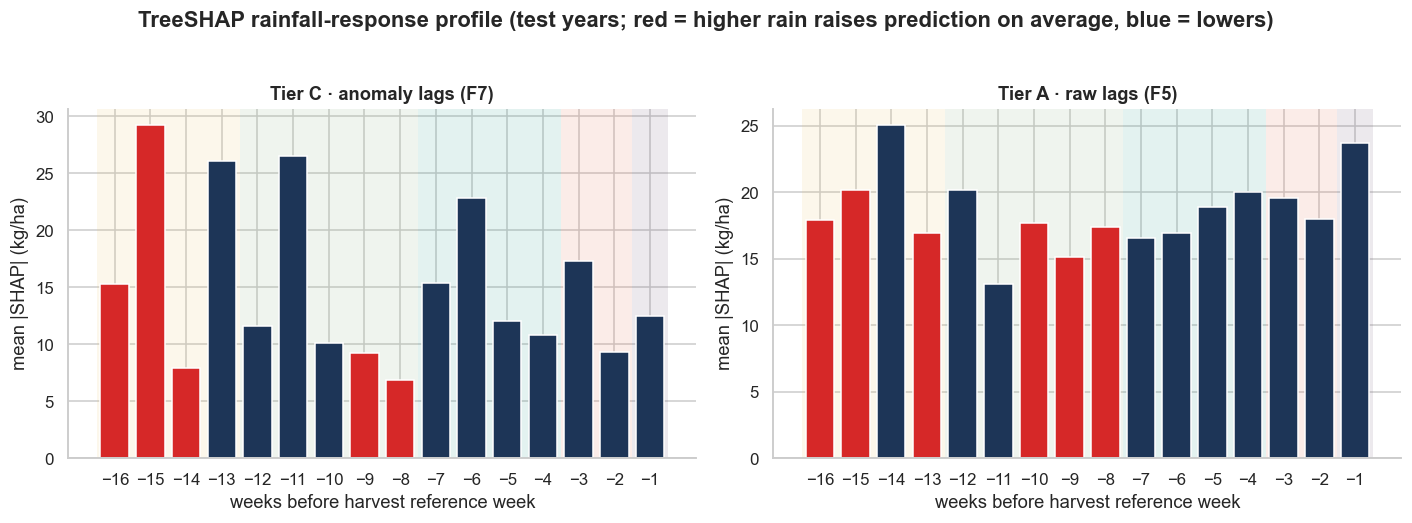

In [4]:
prof = {}; shp = {}
for key, pref in [(("C_anomaly", "F7_Lag16_Anomaly"), "Rain_Anom_Lag_"), (("C_anomaly", "F5_Lag16"), "Rain_Lag_"), (("A_weather_only", "F5_Lag16"), "Rain_Lag_"), (("A_weather_only", "F7_Lag16_Anomaly"), "Rain_Anom_Lag_")]:
    m, X, y, names, base = models[key]
    sv = xgb_shap(m, X["test"], names); shp[key] = sv
    prof[key] = lag_profile(sv, prefix=pref)
    # additivity check: SHAP + bias reproduces the prediction
    chk = np.abs(sv.sum(axis=1).values - m.predict(X["test"])).max(); print(key, "max |ΣSHAP − prediction| =", f"{chk:.2e}")
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False)
for ax, key, ttl in zip(axs, [("C_anomaly", "F7_Lag16_Anomaly"), ("A_weather_only", "F5_Lag16")], ["Tier C · anomaly lags (F7)", "Tier A · raw lags (F5)"]):
    p = prof[key]; stage_bands(ax)
    ax.bar(p.weeks_before_harvest, p.mean_abs_shap, color=["#d62828" if s > 0 else "#1d3557" for s in p.mean_shap], width=.8)
    ax.set_xlabel("weeks before harvest reference week"); ax.set_ylabel("mean |SHAP| (kg/ha)"); ax.set_title(ttl)
    ax.set_xticks(range(-16, 0))
fig.suptitle("TreeSHAP rainfall-response profile (test years; red = higher rain raises prediction on average, blue = lowers)", y=1.03, fontweight="bold")
plt.tight_layout(); savefig("p2_10_shap_profile"); plt.show()

saved -> results/figures/p2_10_shap_dependence_top_weeks.png


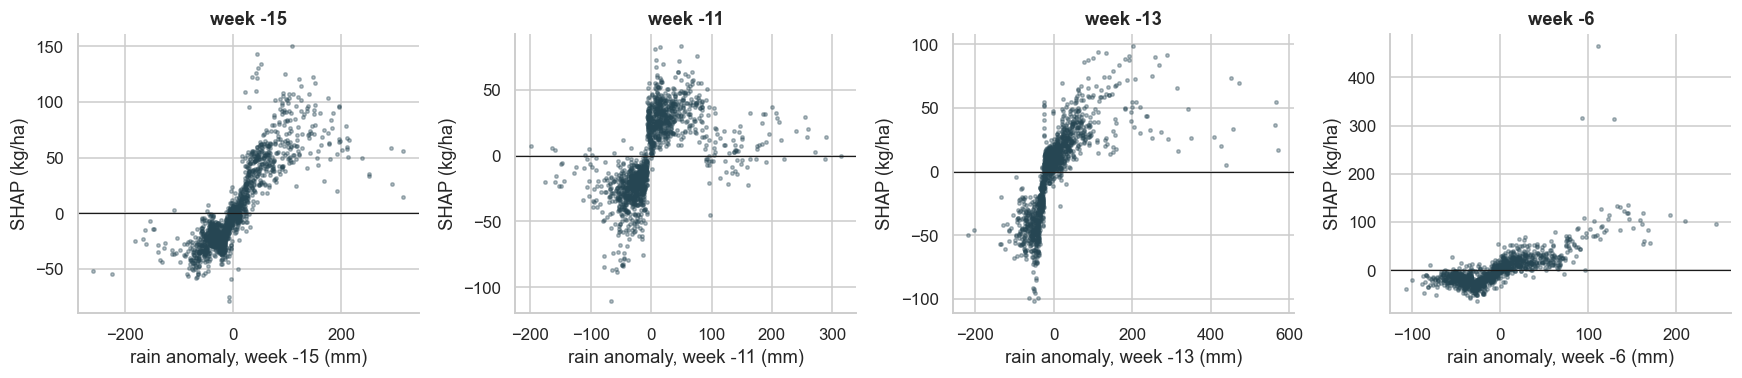

In [5]:
# SHAP dependence of the most important weeks (tier C, anomaly lags)
key = ("C_anomaly", "F7_Lag16_Anomaly"); m, X, y, names, base = models[key]; sv = shp[key]
top = prof[key].sort_values("mean_abs_shap", ascending=False).head(4)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (_, r) in zip(axs, top.iterrows()):
    j = names.index(r.lag); ax.scatter(X["test"][:, j], sv[r.lag], s=5, alpha=.35, color="#264653")
    ax.axhline(0, color="k", lw=.8); ax.set_xlabel(f"rain anomaly, week {int(r.weeks_before_harvest)} (mm)"); ax.set_ylabel("SHAP (kg/ha)"); ax.set_title(f"week {int(r.weeks_before_harvest)}")
plt.tight_layout(); savefig("p2_10_shap_dependence_top_weeks"); plt.show()

## 2 · Stage-level view and group importance

saved -> results/figures/p2_10_stage_importance.png


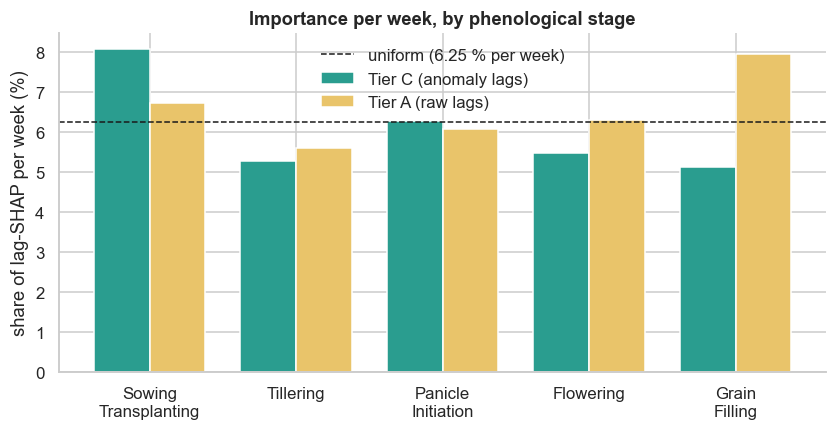

,stage,mean_abs_shap,n_weeks,share,share_per_week
0,S1_Sowing_Transplanting,78.499,4,0.323,0.081
1,S2_Tillering,64.261,5,0.264,0.053
2,S3_Panicle_Initiation,61.128,4,0.252,0.063
3,S4_Flowering,26.593,2,0.109,0.055
4,S5_Grain_Filling,12.480,1,0.051,0.051


In [6]:
sp = stage_profile(prof[("C_anomaly", "F7_Lag16_Anomaly")]); sp.to_csv(TAB/"p2_shap_stage_profile_tierC.csv", index=False)
sp2 = stage_profile(prof[("A_weather_only", "F5_Lag16")]); sp2.to_csv(TAB/"p2_shap_stage_profile_tierA.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
w = .38; x = np.arange(len(sp))
ax.bar(x - w/2, sp.share_per_week * 100, w, label="Tier C (anomaly lags)", color="#2a9d8f"); ax.bar(x + w/2, sp2.share_per_week * 100, w, label="Tier A (raw lags)", color="#e9c46a")
ax.axhline(100 / 16, color="k", ls="--", lw=1, label="uniform (6.25 % per week)"); ax.set_xticks(x); ax.set_xticklabels([s.split("_", 1)[1].replace("_", "\n") for s in sp.stage])
ax.set_ylabel("share of lag-SHAP per week (%)"); ax.legend(frameon=False); ax.set_title("Importance per week, by phenological stage")
savefig("p2_10_stage_importance"); plt.show(); sp.round(3)

In [7]:
rows = []
for key in [("C_anomaly", "F7_Lag16_Anomaly"), ("A_weather_only", "F5_Lag16")]:
    m, X, y, names, base = models[key]
    pref = "Rain_Anom_Lag_" if "F7" in key[1] else "Rain_Lag_"
    groups = {"16 weekly rainfall lags (jointly)": [f"{pref}{k}" for k in range(1, 17)], "IMD_Tmax": ["IMD_Tmax"], "state fixed effects": [n for n in names if n.startswith("State_Clean_")]}
    gi = group_permutation_importance(m, X["test"], y["test"], names, groups, n_repeats=15); gi.insert(0, "tier", key[0]); rows.append(gi)
    wk = permutation_week_importance(m, X["test"], y["test"], names, n_repeats=15, prefix=pref); wk.to_csv(TAB/f"p2_perm_week_importance_{key[0]}.csv", index=False)
G = pd.concat(rows); G.to_csv(TAB/"p2_group_permutation_importance.csv", index=False); G

,tier,group,mae_increase,sd
0,C_anomaly,16 weekly rainfall lags (jointly),10.964,1.837
2,C_anomaly,state fixed effects,2.812,1.260
1,C_anomaly,IMD_Tmax,0.044,0.527
2,A_weather_only,state fixed effects,297.076,13.029
0,A_weather_only,16 weekly rainfall lags (jointly),23.916,4.144
1,A_weather_only,IMD_Tmax,4.145,3.108


## 3 · Panel fixed-effects distributed-lag regression (explanatory lens)

$$\log y_{it} = \sum_{k=1}^{16}\beta_k\,\text{RainAnom}_{it,k} + \alpha_i + \gamma_t + \varepsilon_{it}$$

Units: $\beta_k\times 100$ = % change in yield per **+100 mm** of rain above the district's normal in week $-k$. District fixed effects absorb
time-invariant productivity, year fixed effects absorb all-India shocks and the technology trend.

N = 10,279 district-years · R² (with FE) = 0.771
H0: all 16 weekly coefficients = 0     :  Wald χ² = 112.4,  p = 1.56e-16
H0: all 16 coefficients EQUAL (timing irrelevant): Wald χ² = 65.2,  p = 3.14e-08


saved -> results/figures/p2_10_panel_fe_profile.png


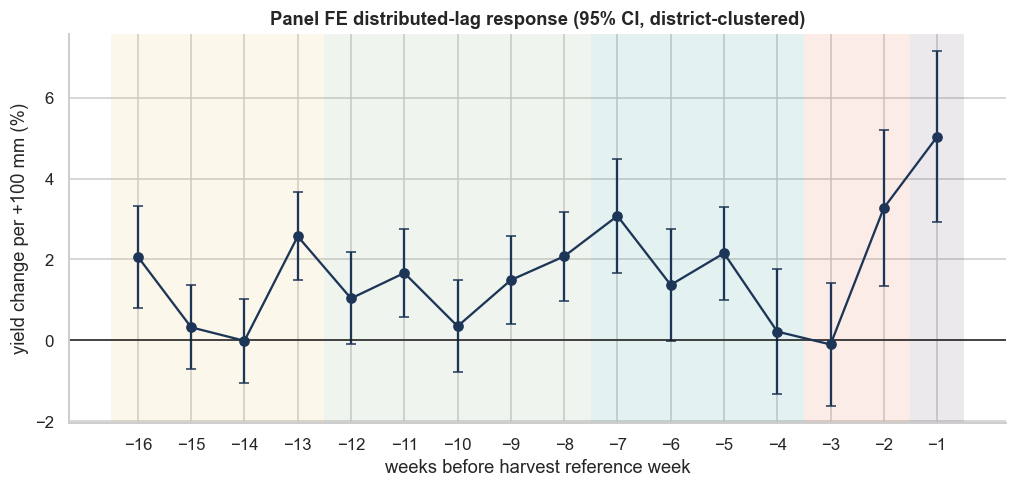

,weeks_before_harvest,coef_pct_per_100mm,ci_lo,ci_hi,p_value
0,-16,2.067,0.810,3.323,0.001
1,-15,0.322,-0.719,1.363,0.545
2,-14,-0.012,-1.053,1.030,0.983
3,-13,2.572,1.485,3.658,0.000
4,-12,1.036,-0.100,2.172,0.074
5,-11,1.665,0.586,2.743,0.002
6,-10,0.347,-0.789,1.483,0.549
7,-9,1.490,0.412,2.568,0.007
8,-8,2.075,0.974,3.177,0.000
9,-7,3.075,1.663,4.487,0.000


In [8]:
res = lag_coefficients(D); tb = res["table"]; tb.to_csv(TAB/"p2_panel_fe_lag_coefficients.csv", index=False)
print(f"N = {res['n']:,} district-years · R² (with FE) = {res['r2']:.3f}")
print("H0: all 16 weekly coefficients = 0     :  Wald χ² = %.1f,  p = %.2e" % res["wald_zero"])
print("H0: all 16 coefficients EQUAL (timing irrelevant): Wald χ² = %.1f,  p = %.2e" % res["wald_equal"])
fig, ax = plt.subplots(figsize=(11, 4.6)); stage_bands(ax)
ax.errorbar(tb.weeks_before_harvest, tb.coef_pct_per_100mm, yerr=[tb.coef_pct_per_100mm - tb.ci_lo, tb.ci_hi - tb.coef_pct_per_100mm], fmt="o-", color="#1d3557", capsize=3)
ax.axhline(0, color="k", lw=1); ax.set_xticks(range(-16, 0)); ax.set_xlabel("weeks before harvest reference week"); ax.set_ylabel("yield change per +100 mm (%)")
ax.set_title("Panel FE distributed-lag response (95% CI, district-clustered)")
savefig("p2_10_panel_fe_profile"); plt.show(); tb.round(3)

In [9]:
st = stage_coefficients(D); st.to_csv(TAB/"p2_panel_fe_stage_coefficients.csv", index=False)
d_ = _prep(D); fe_only = fit_fe(d_, ["IMD_Tmax"], "C(dist) + C(Year)")
mt = fit_fe(d_.assign(tot=D.Rain_Anom_Total16 / 100), ["tot"]); ml = res["model"]
r2 = {"district+year FE (+Tmax)": fe_only.rsquared, "+ seasonal total anomaly": mt.rsquared, "+ 16 weekly anomalies": ml.rsquared}
within = lambda r: (r - fe_only.rsquared) / (1 - fe_only.rsquared)
print({k: round(v, 4) for k, v in r2.items()})
print("share of the FE-residual variance explained by the seasonal total  : %.2f %%" % (100 * within(mt.rsquared)))
print("share of the FE-residual variance explained by the 16 weekly lags  : %.2f %%" % (100 * within(ml.rsquared)))
pd.DataFrame([dict(model=k, R2=v, incremental_within_R2_pct=100 * within(v)) for k, v in r2.items()]).to_csv(TAB/"p2_panel_fe_r2_decomposition.csv", index=False)
st.round(3)

{'district+year FE (+Tmax)': np.float64(0.7675), '+ seasonal total anomaly': np.float64(0.7698), '+ 16 weekly anomalies': np.float64(0.771)}
share of the FE-residual variance explained by the seasonal total  : 1.01 %
share of the FE-residual variance explained by the 16 weekly lags  : 1.53 %


,stage,coef_pct_per_100mm,ci_lo,ci_hi,p_value
0,S1_Sowing_Transplanting,1.125,0.502,1.747,0.000
1,S2_Tillering,1.343,0.833,1.854,0.000
2,S3_Panicle_Initiation,1.879,1.143,2.616,0.000
3,S4_Flowering,1.394,0.082,2.707,0.037
4,S5_Grain_Filling,5.225,3.145,7.305,0.000


## 4 · Do the three lenses agree?

                  TreeSHAP |mean|  permutation ΔMAE  panel |β|
TreeSHAP |mean|             1.000             0.290      0.050
permutation ΔMAE            0.290             1.000      0.490
panel |β|                   0.050             0.490      1.000
sign agreement between mean SHAP and panel β across the 16 weeks: 0.31


saved -> results/figures/p2_10_triangulation.png


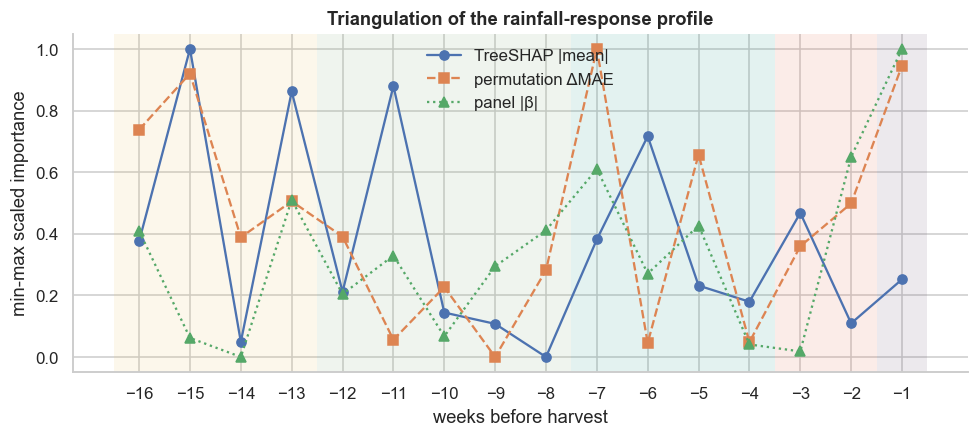

In [10]:
from scipy.stats import spearmanr, pearsonr
a = prof[("C_anomaly", "F7_Lag16_Anomaly")].set_index("weeks_before_harvest").mean_abs_shap
b = pd.read_csv(TAB/"p2_perm_week_importance_C_anomaly.csv").set_index("weeks_before_harvest").mae_increase
c = tb.set_index("weeks_before_harvest").coef_pct_per_100mm.abs()
T = pd.DataFrame({"TreeSHAP |mean|": a, "permutation ΔMAE": b, "panel |β|": c})
print(T.corr(method="spearman").round(2))
sgn = (np.sign(prof[("C_anomaly", "F7_Lag16_Anomaly")].set_index("weeks_before_harvest").mean_shap) == np.sign(tb.set_index("weeks_before_harvest").coef_pct_per_100mm)).mean()
print("sign agreement between mean SHAP and panel β across the 16 weeks:", round(float(sgn), 2))
Z = (T - T.min()) / (T.max() - T.min())
fig, ax = plt.subplots(figsize=(10.5, 4));
for col, mk in zip(Z.columns, ["o-", "s--", "^:"]): ax.plot(Z.index, Z[col], mk, label=col)
stage_bands(ax); ax.set_xticks(range(-16, 0)); ax.set_ylabel("min-max scaled importance"); ax.set_xlabel("weeks before harvest"); ax.legend(frameon=False); ax.set_title("Triangulation of the rainfall-response profile")
savefig("p2_10_triangulation"); plt.show()

## 5 · Is the response non-linear? And does it differ between irrigated and rain-fed states?

predominantly irrigated | equal-coefficient test p = 6.26e-14 | zero test p = 9.00e-16


rain-fed / mixed | equal-coefficient test p = 4.72e-07 | zero test p = 4.79e-16


saved -> results/figures/p2_10_nonlinearity_and_regimes.png


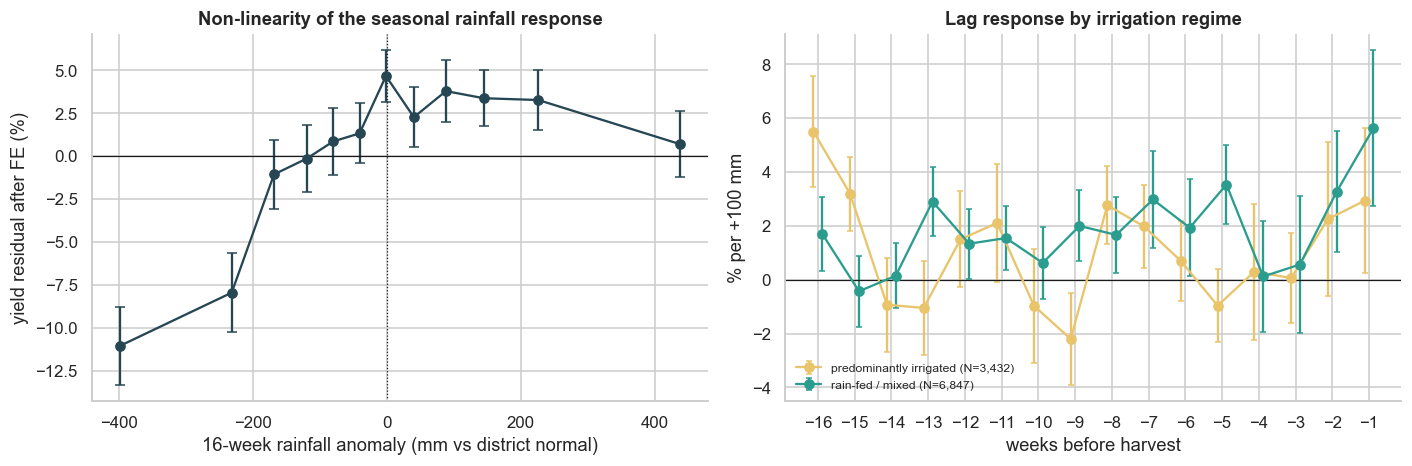

In [11]:
d_ = _prep(D).copy(); d_["tot"] = D.Rain_Anom_Total16
# residualise log yield on district + year FE, then bin by total anomaly (in district-normal units)
mfe = fit_fe(d_, ["IMD_Tmax"], "C(dist) + C(Year)"); d_["resid"] = mfe.resid
d_["tot_bin"] = pd.qcut(d_.tot, 12); bm = d_.groupby("tot_bin").agg(x=("tot", "mean"), y=("resid", "mean"), se=("resid", lambda s: s.std() / np.sqrt(len(s)))).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
axs[0].errorbar(bm.x, bm.y * 100, yerr=bm.se * 196, fmt="o-", color="#264653", capsize=3); axs[0].axhline(0, color="k", lw=.8); axs[0].axvline(0, color="k", lw=.8, ls=":")
axs[0].set_xlabel("16-week rainfall anomaly (mm vs district normal)"); axs[0].set_ylabel("yield residual after FE (%)"); axs[0].set_title("Non-linearity of the seasonal rainfall response")
IRR = {"Punjab", "Haryana", "Uttar Pradesh", "Andhra Pradesh", "Telangana", "Tamil Nadu"}
for name, mask, col in [("predominantly irrigated", D.State_Clean.isin(IRR), "#e9c46a"), ("rain-fed / mixed", ~D.State_Clean.isin(IRR), "#2a9d8f")]:
    r_ = lag_coefficients(D[mask]); t_ = r_["table"]
    axs[1].errorbar(t_.weeks_before_harvest + (.12 if "rain" in name else -.12), t_.coef_pct_per_100mm, yerr=[t_.coef_pct_per_100mm - t_.ci_lo, t_.ci_hi - t_.coef_pct_per_100mm], fmt="o-", color=col, capsize=2, label=f"{name} (N={r_['n']:,})")
    print(name, "| equal-coefficient test p = %.2e | zero test p = %.2e" % (r_["wald_equal"][1], r_["wald_zero"][1]))
    t_.assign(group=name).to_csv(TAB/f"p2_panel_fe_{name.split()[0].replace('/', '')}.csv", index=False)
axs[1].axhline(0, color="k", lw=.8); axs[1].set_xticks(range(-16, 0)); axs[1].set_xlabel("weeks before harvest"); axs[1].set_ylabel("% per +100 mm"); axs[1].legend(frameon=False, fontsize=8)
axs[1].set_title("Lag response by irrigation regime"); plt.tight_layout(); savefig("p2_10_nonlinearity_and_regimes"); plt.show()

### Take-aways of notebook 10
The explanatory regression and the model-based importances can be compared directly (table above). The key distinction the project must
keep clear: a **statistically structured** rainfall-timing response (explanatory) is not the same thing as an **out-of-sample forecasting gain**
(notebooks 07-09); notebook 11 reconciles the two.